In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

0 - вовремя, 1 - не вовремя

In [2]:
df = pd.read_csv("Train.csv")
X= df[["Cost_of_the_Product", "Weight_in_gms"]].values
y = df["Reached.on.Time_Y.N"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(np.round(X_train[:3], 2))

[[-0.67  0.31]
 [-0.17  0.53]
 [ 1.38 -1.59]]


In [ ]:
svm_linear = SVC(kernel="linear", C=1.0, gamma="scale", random_state=42)
svm_linear.fit(X_train, y_train)

y_pred_lin = svm_linear.predict(X_test)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность линейного SVM: 67.3%


In [4]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность SVM (Ядро RBF): {acc_rbf*100:.1f}%")

Точность SVM (Ядро RBF): 68.1%


Точность линейной модели = 67,3%, а модели с ядром = 68,1%. Вторая показала немного лучший результат, но разница совсем маленькая, получается, что данные признаки не позволяют достаточно точно разделить классы

In [9]:
svm_с001 = SVC(kernel="linear", C=0.01, gamma="scale", random_state=42)
svm_с1000 = SVC(kernel="linear", C=1000, gamma="scale", random_state=42)

svm_с001.fit(X_train, y_train)
svm_с1000.fit(X_train, y_train)

y_pred_с001 = svm_с001.predict(X_test)
y_pred_с1000 = svm_с1000.predict(X_test)

acc_с001 = accuracy_score(y_test, y_pred_с001)
acc_с1000 = accuracy_score(y_test, y_pred_с1000)

print(f"Точность Линейного SVM при С = 0.01: {acc_с001*100:.1f}%")
print(f"Точность Линейного SVM при С = 1000: {acc_с1000*100:.1f}%")

Точность Линейного SVM при С = 0.01: 59.3%
Точность Линейного SVM при С = 1000: 67.3%


При С = 0,01 модель допускает больше ошибок и становится меннее точной, а при C = 1000 модель не повышает точность, а остается такой же, как и при С = 1, значит увеличение С не повышает точность модели в этом случае

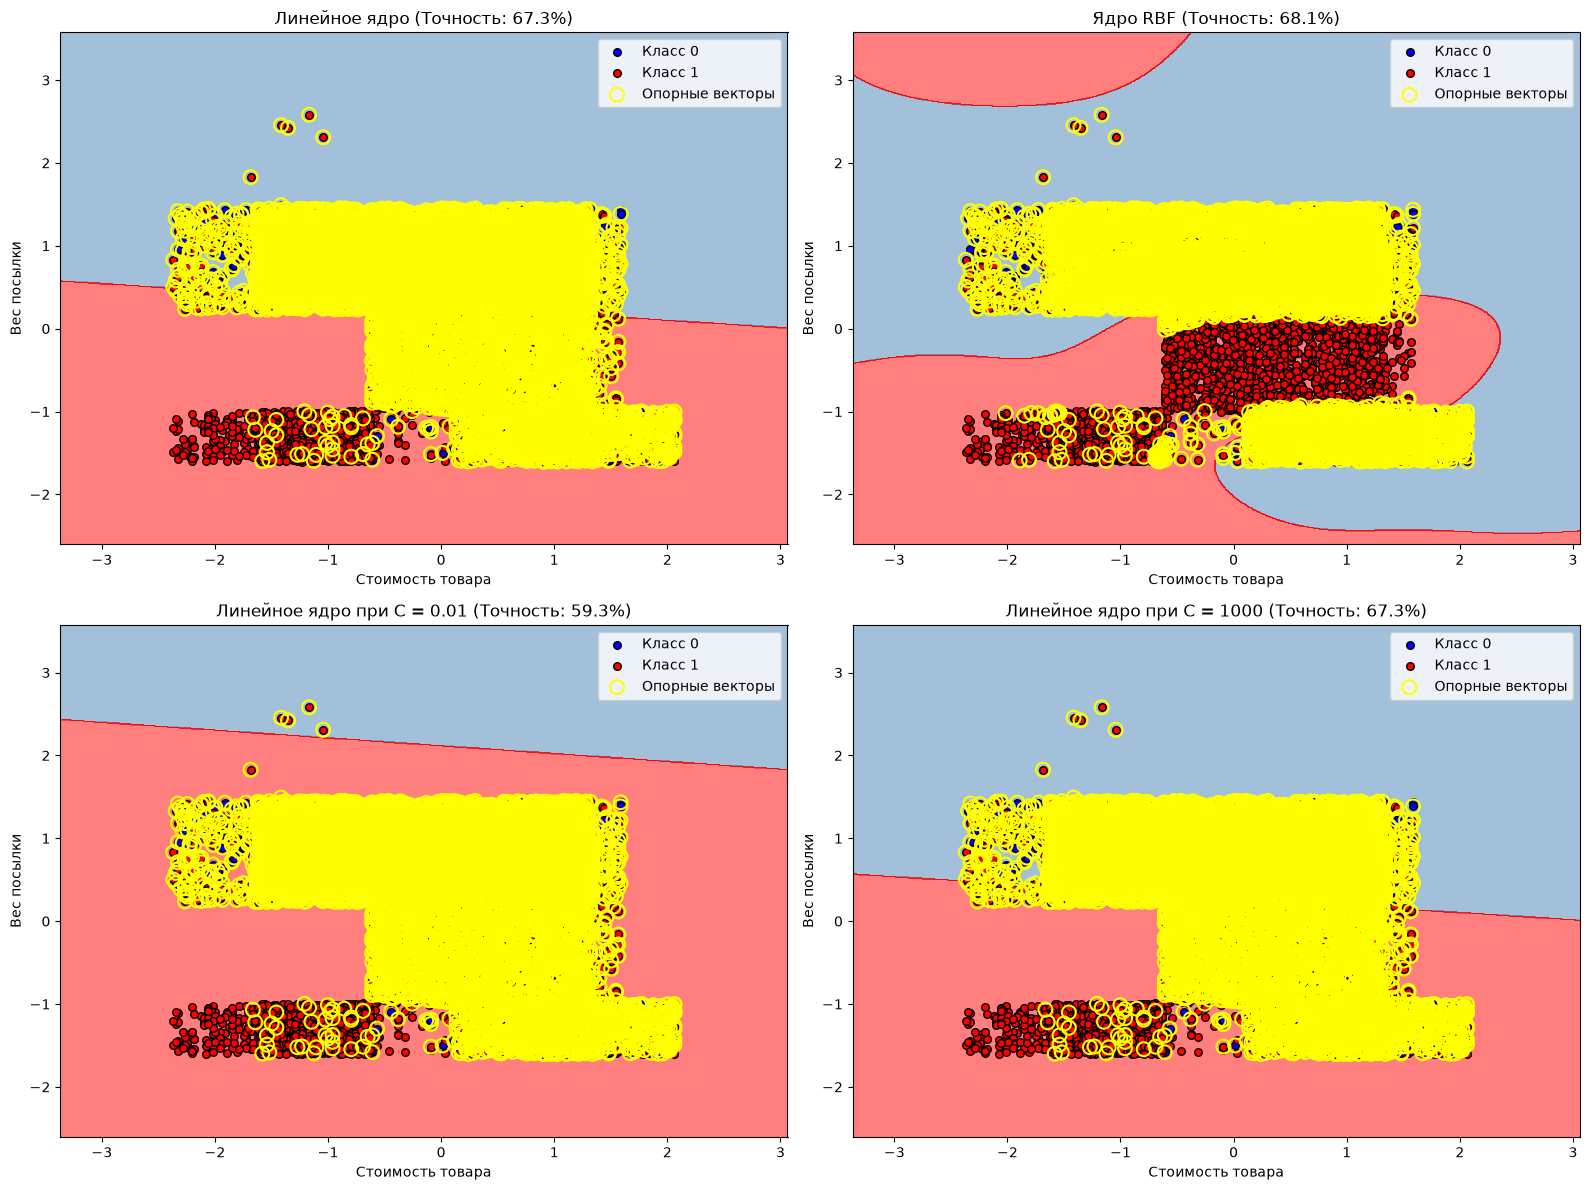

In [11]:
def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train, y_train
    X1, X2 = np.meshgrid(
        np.arange(
            start=X_set[:, 0].min() - 1, stop=X_set[:,0].max() + 1, step=0.01
        ),
        np.arange(
            start=X_set[:, 1].min() - 1, stop=X_set[:,1].max() + 1, step=0.01
        ),
    )
    ax.contourf(
        X1,
        X2,
        model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "red")),
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            label=f"Класс {j}",
            edgecolors="k",
            s=30,
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="yellow",
        s=100,
        linewidth=1.5,
        label="Опорные векторы",
    )

    ax.set_title(title)
    ax.set_xlabel("Стоимость товара")
    ax.set_ylabel("Вес посылки")
    ax.legend()


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

plot_decision_boundary(
    svm_linear, axes[0, 0], f"Линейное ядро (Точность: {acc_lin*100:.1f}%)"
)
plot_decision_boundary(svm_rbf, axes[0, 1], f"Ядро RBF (Точность: {acc_rbf*100:.1f}%)")
plot_decision_boundary(
    svm_с001, axes[1, 0], f"Линейное ядро при С = 0.01 (Точность: {acc_с001*100:.1f}%)"
)
plot_decision_boundary(
    svm_с1000, axes[1, 1], f"Линейное ядро при С = 1000 (Точность: {acc_с1000*100:.1f}%)"
)

plt.tight_layout()
plt.show()

На графиках есть большое количество опорных векторов, это говорит о том, что классы сильно пересекаются и модели сложно предсказать точно. Линейная модель разделяет данные прямой границей, а модель с ядром использует нелинейную границу, при этом обе модели допускают ошибки, так как классы частично пересекаются. При изменении С граница немного меняется, но все равно не делит классы полностью

Лучший результат вышел у модели с ядром = 68,1%, однако этой точности все равно недостаточно для надежного прогнозирования своевременности доставки. Компании стоит учитывать и другие признаки, чтобы более точно определять задержится доставка посылки или нет